# Etapa 5 — Evaluación y validación

**Modelo de Machine Learning para el cribado técnico de reservorios candidatos a waterflooding**

Proyecto de titulación — Maestría en Petróleos, ESPOL

---

| Paso | Contenido |
|---|---|
| 5.1 | Evaluación única sobre el conjunto de prueba (1 000 escenarios) |
| 5.2 | Comparación entrenamiento / validación cruzada / prueba |
| 5.3 | Matriz de confusión, precisión, recall, F1, exactitud y AUC-ROC |
| 5.4 | Importancia de variables y controles negativos |
| 5.5 | Comparación con el cribado tradicional por rangos |
| 5.6 | Caso de referencia con datos de campo (contexto, no validación) |

**Reglas de esta etapa.** Los hiperparámetros son los de la Etapa 4 y no se vuelve a ajustar nada.
El modelo final se elige por su F1 en validación cruzada, antes de mirar la prueba. El conjunto de
prueba se usa una sola vez, para informar el desempeño esperado.

## 1. Configuración del entorno

In [1]:
import os, sys, subprocess, json

REPO_URL = "https://github.com/phabelog/waterflooding-ml-screening.git"
REPO_DIR = "waterflooding-ml-screening"

if os.path.isdir("src/evaluation"):
    REPO_ROOT = "."
else:
    if not os.path.isdir(REPO_DIR):
        subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
    else:
        subprocess.run(["git", "-C", REPO_DIR, "pull", "-q"], check=True)
    REPO_ROOT = REPO_DIR

sys.path.insert(0, os.path.join(REPO_ROOT, "src", "evaluation"))
print("Repositorio listo en:", os.path.abspath(REPO_ROOT))

Repositorio listo en: /content/waterflooding-ml-screening


In [2]:
import sklearn, xgboost, pandas as pd
print("scikit-learn:", sklearn.__version__, "| xgboost:", xgboost.__version__)

import evaluate as ev, figures, train_models as tm

df = pd.read_csv(os.path.join(REPO_ROOT, "data", "synthetic", "synthetic_dataset.csv"))
e4 = tm.load_results(os.path.join(REPO_ROOT, "results", "etapa4_resultados.json"))
print("Escenarios:", len(df), "| modelos de la Etapa 4:", ", ".join(e4["modelos"]))

scikit-learn: 1.6.1 | xgboost: 3.4.1
Escenarios: 5000 | modelos de la Etapa 4: arbol_decision, random_forest, xgboost, svm


## 2. Evaluación completa

Ajusta los cuatro modelos con los 4 000 escenarios de entrenamiento y los evalúa. Tarda de 2 a 4 minutos.

In [3]:
resultados, objetos = ev.run_evaluation(df, e4, n_jobs=-1)

Modelos ajustados con el entrenamiento: arbol_decision, random_forest, xgboost, svm
Modelo final (mayor F1 en validación cruzada): XGBoost


## 3. Entrenamiento, validación cruzada y prueba

In [4]:
tabla = objetos["tabla"].round(3)
tabla.index = tabla.index.set_levels([[tm.MODEL_LABELS[m] for m in tabla.index.levels[0]], tabla.index.levels[1]])
tabla

f1  precision  recall  accuracy  \
modelo                   conjunto                                            
Árbol de decisión (base) entrenamiento  0.940      0.921   0.959     0.952   
                         validacion     0.912      0.885   0.942     0.930   
                         prueba         0.895      0.881   0.910     0.917   
Random Forest            entrenamiento  1.000      1.000   1.000     1.000   
                         validacion     0.932      0.922   0.942     0.946   
                         prueba         0.919      0.905   0.933     0.936   
XGBoost                  entrenamiento  1.000      1.000   1.000     1.000   
                         validacion     0.953      0.938   0.967     0.962   
                         prueba         0.944      0.928   0.961     0.956   
SVM                      entrenamiento  0.909      0.872   0.949     0.926   
                         validacion     0.839      0.808   0.873     0.870   
                         prueba         0.842      0.820   0.866     0.874   

                                        auc_roc  
modelo                   conjunto                
Árbol de decisión (base) entrenamiento    0.992  
                         validacion       0.967  
                         prueba           0.961  
Random Forest            entrenamiento    1.000  
                         validacion       0.988  
                         prueba           0.984  
XGBoost                  entrenamiento    1.000  
                         validacion       0.995  
                         prueba           0.993  
SVM                      entrenamiento    0.981  
                         validacion       0.949  
                         prueba           0.950

In [5]:
print("Modelo final:", tm.MODEL_LABELS[resultados["modelo_final"]])
print("Matriz de confusión en la prueba:", resultados["modelos"][resultados["modelo_final"]]["matriz_confusion_prueba"])

Modelo final: XGBoost
Matriz de confusión en la prueba: {'tn': 582, 'fp': 29, 'fn': 15, 'tp': 374}


## 4. Importancia de variables y controles negativos

In [6]:
objetos["importancia"].round(4)

,importancia,desv,control_negativo
muo_cp,0.2330,0.0131,False
So_current,0.1980,0.0125,False
Vdp,0.1565,0.0112,False
k_md,0.0997,0.0067,False
krw_max,0.0511,0.0058,False
h_net_ft,0.0487,0.0057,False
Swi,0.0207,0.0044,False
Sor,0.0174,0.0051,False
no,0.0139,0.0043,False
kro_max,0.0088,0.0034,False


## 5. Comparación con el cribado tradicional por rangos

In [7]:
fin = resultados["modelo_final"]
pd.DataFrame({"Clasificador trivial": resultados["clasificador_trivial_prueba"],
              "Cribado por rangos": {k: v for k, v in resultados["cribado_tradicional_prueba"].items() if k != "matriz_confusion"},
              tm.MODEL_LABELS[fin]: resultados["modelos"][fin]["prueba"]}).round(3)

,Clasificador trivial,Cribado por rangos,XGBoost
f1,0.560,0.784,0.944
precision,0.389,0.645,0.928
recall,1.000,1.000,0.961
accuracy,0.389,0.786,0.956
auc_roc,0.500,NaN,0.993


## 6. Caso de referencia (datos de campo anonimizados; contexto, no validación)

In [8]:
print(json.dumps(resultados["caso_referencia"], ensure_ascii=False, indent=2))
pd.DataFrame(ev.REFERENCE_TABLE, columns=["Variable", "Unidad", "Rango sintético", "Valor de campo", "Dentro del rango"])

{
  "realizaciones": 2000,
  "fraccion_apta_fisica": 0.6015,
  "fraccion_apta_modelo": 0.5315,
  "coincidencia_modelo_fisica": 0.918,
  "probabilidad_media_modelo": 0.5184157490730286,
  "M_p10_p50_p90": [
    3.016011277125471,
    7.037926789537461,
    14.968819787583607
  ],
  "RF_p10_p50_p90": [
    0.13345762508277365,
    0.2982226346414348,
    0.40750853045164714
  ],
  "q_iny_p10_p50_p90": [
    9529.482611998972,
    14138.435174357965,
    23416.12729897133
  ],
  "muo_p10_p50_p90": [
    3.485505636041366,
    7.553037740388727,
    15.74263633292662
  ],
  "realizaciones_fuera_de_dominio": 0,
  "motivos_rechazo_fisica": {
    "M": 548,
    "Vdp": 324,
    "RF": 262
  }
}


,Variable,Unidad,Rango sintético,Valor de campo,Dentro del rango
0,Permeabilidad,mD,5 – 3 000,680 (217 – 1 180),Sí
1,Porosidad,fracción,0.08 – 0.25,0.16 (0.13 – 0.19),Sí
2,Espesor neto,ft,5 – 80,43 (28 – 56),Sí
3,Gravedad API,°API,14 – 35,18.5 – 19,Sí
4,Profundidad vertical,ft,7 000 – 10 500,9 464 – 9 740,Sí
5,Saturación de agua irreducible,fracción,0.10 – 0.45,0.06 – 0.21,Parcial
6,Saturación residual de petróleo,fracción,0.15 – 0.35,0.29 – 0.38,Parcial
7,krw máximo,fracción,0.15 – 0.55,< 0.25,Sí


## 7. Figuras y archivo de resultados

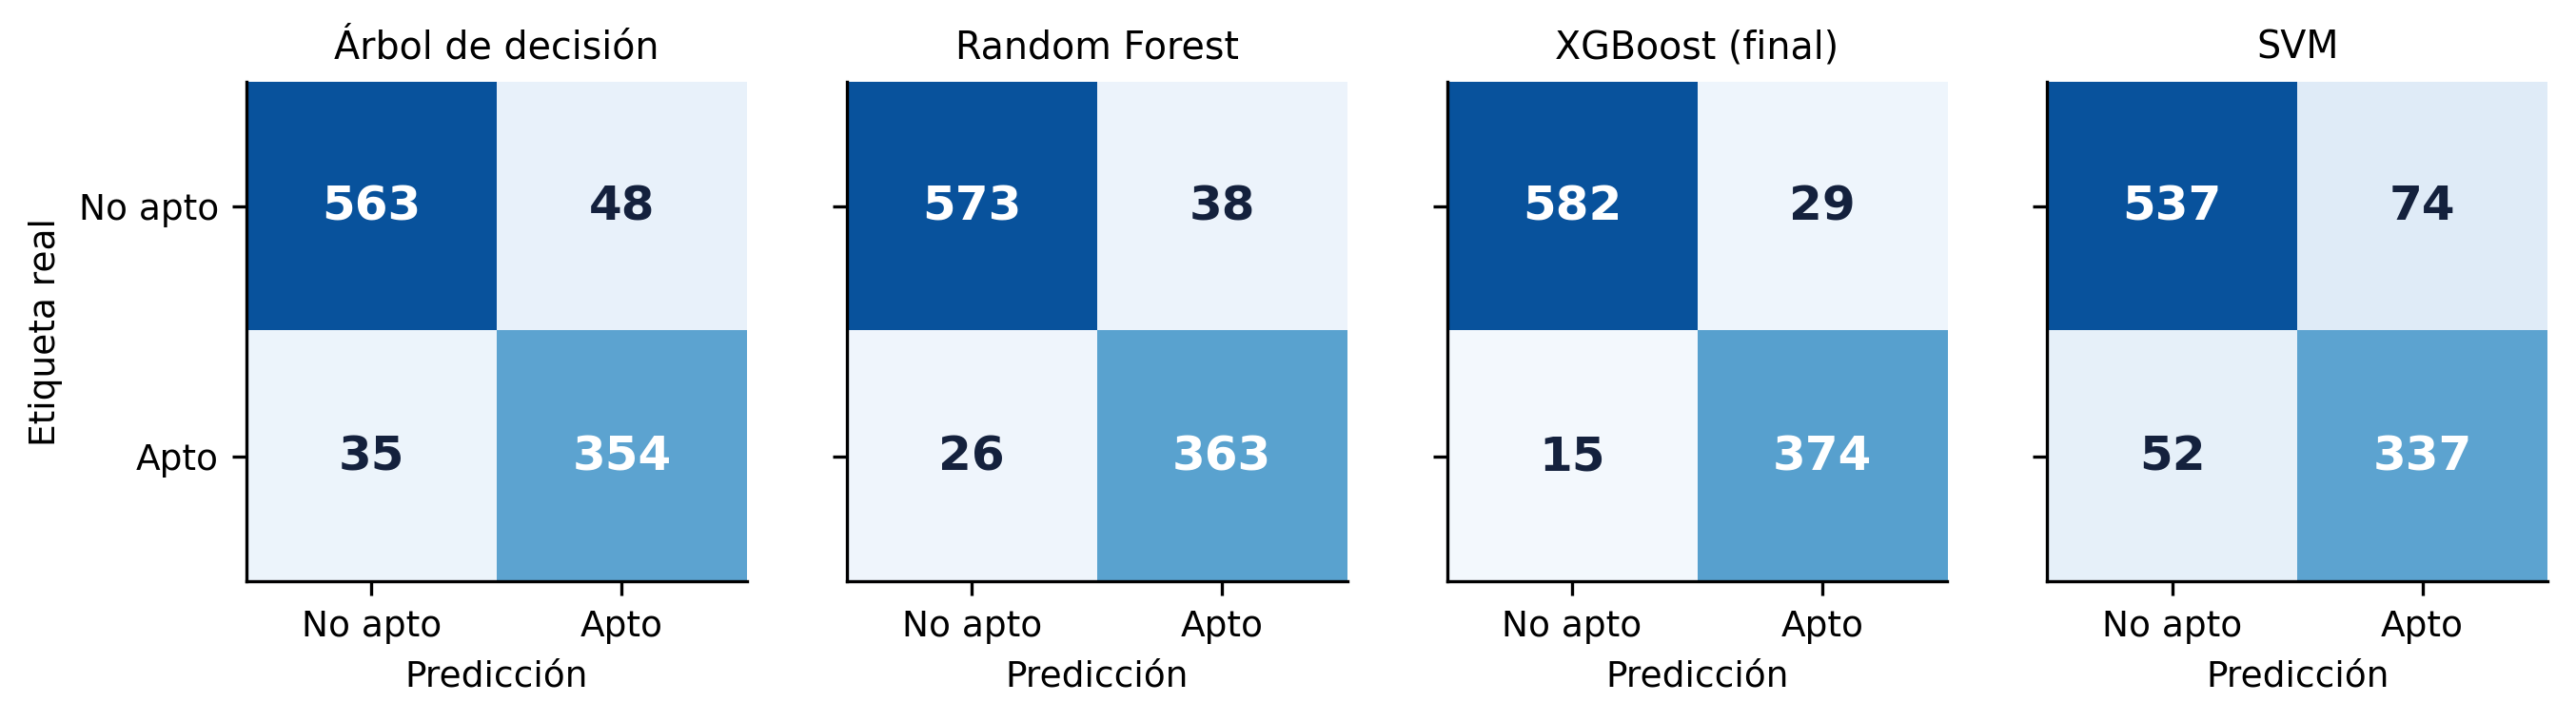

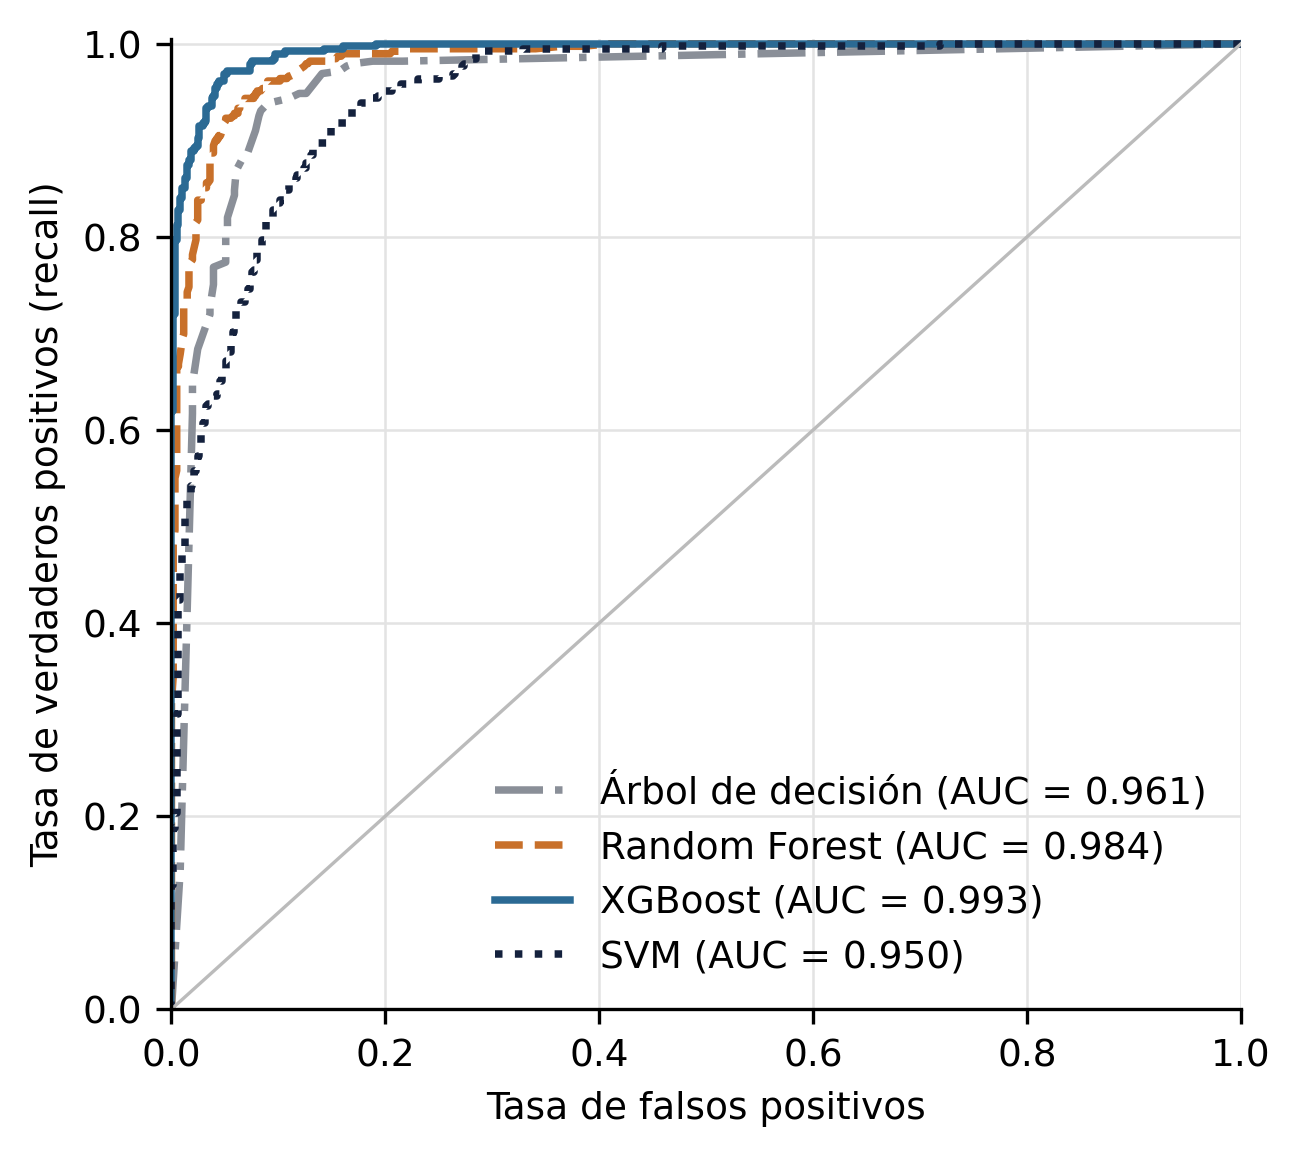

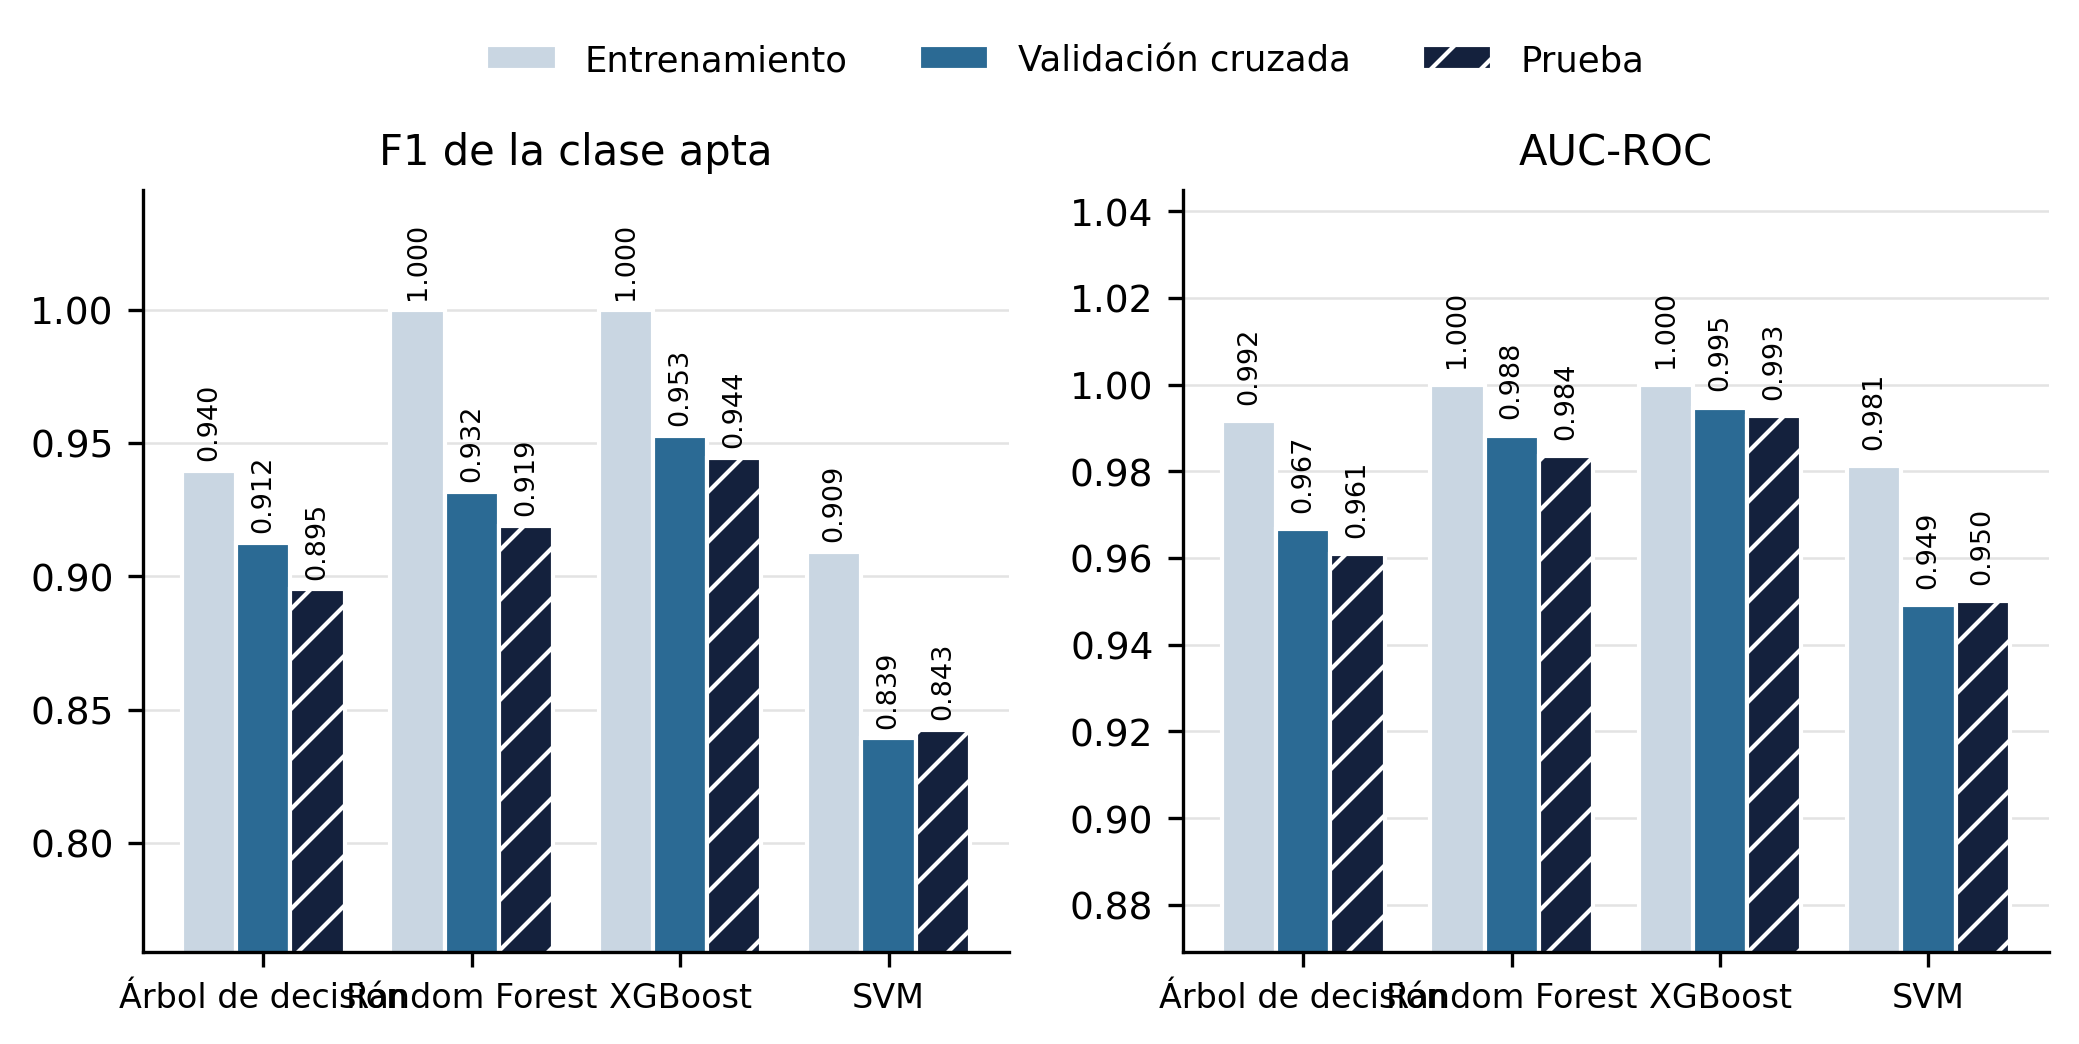

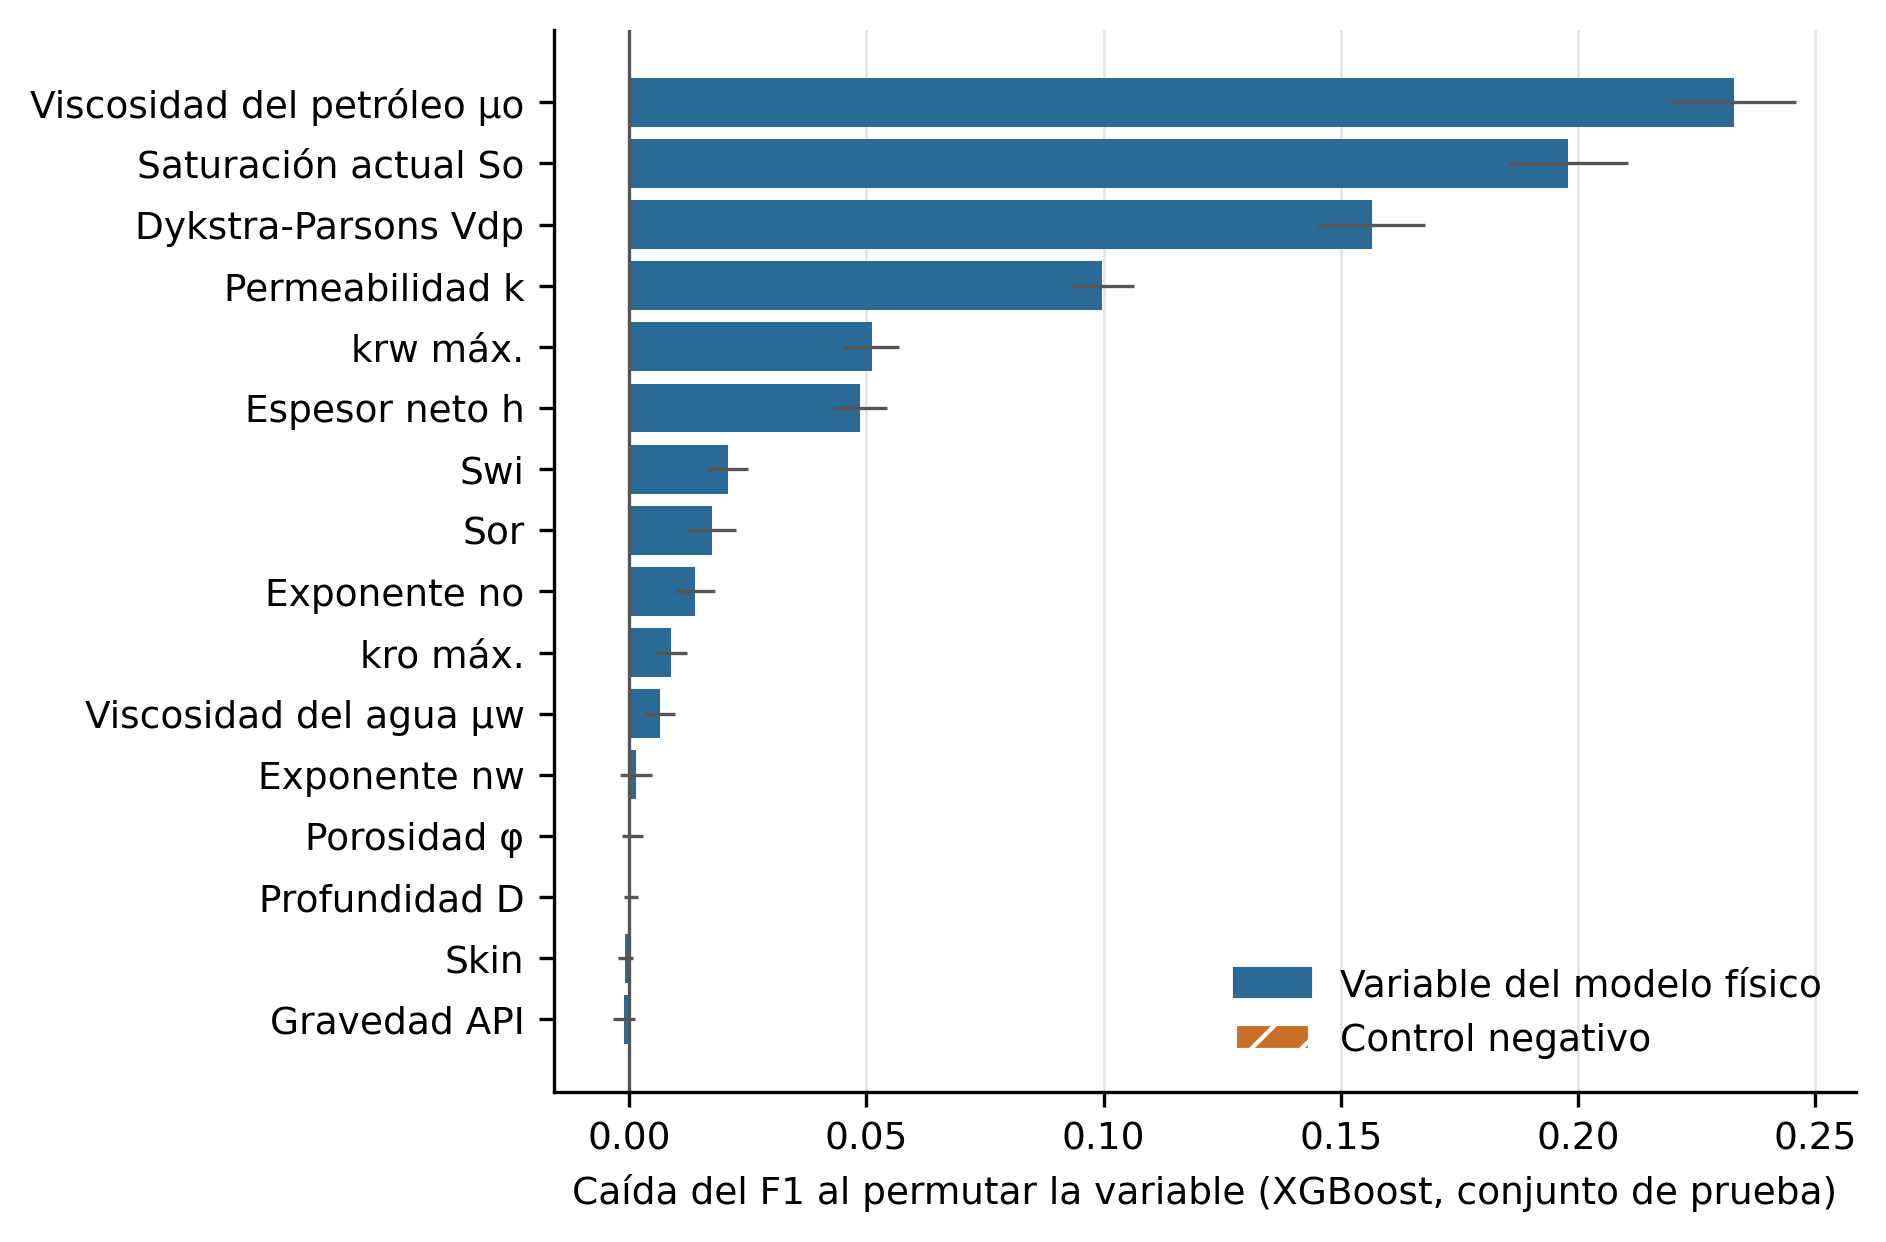

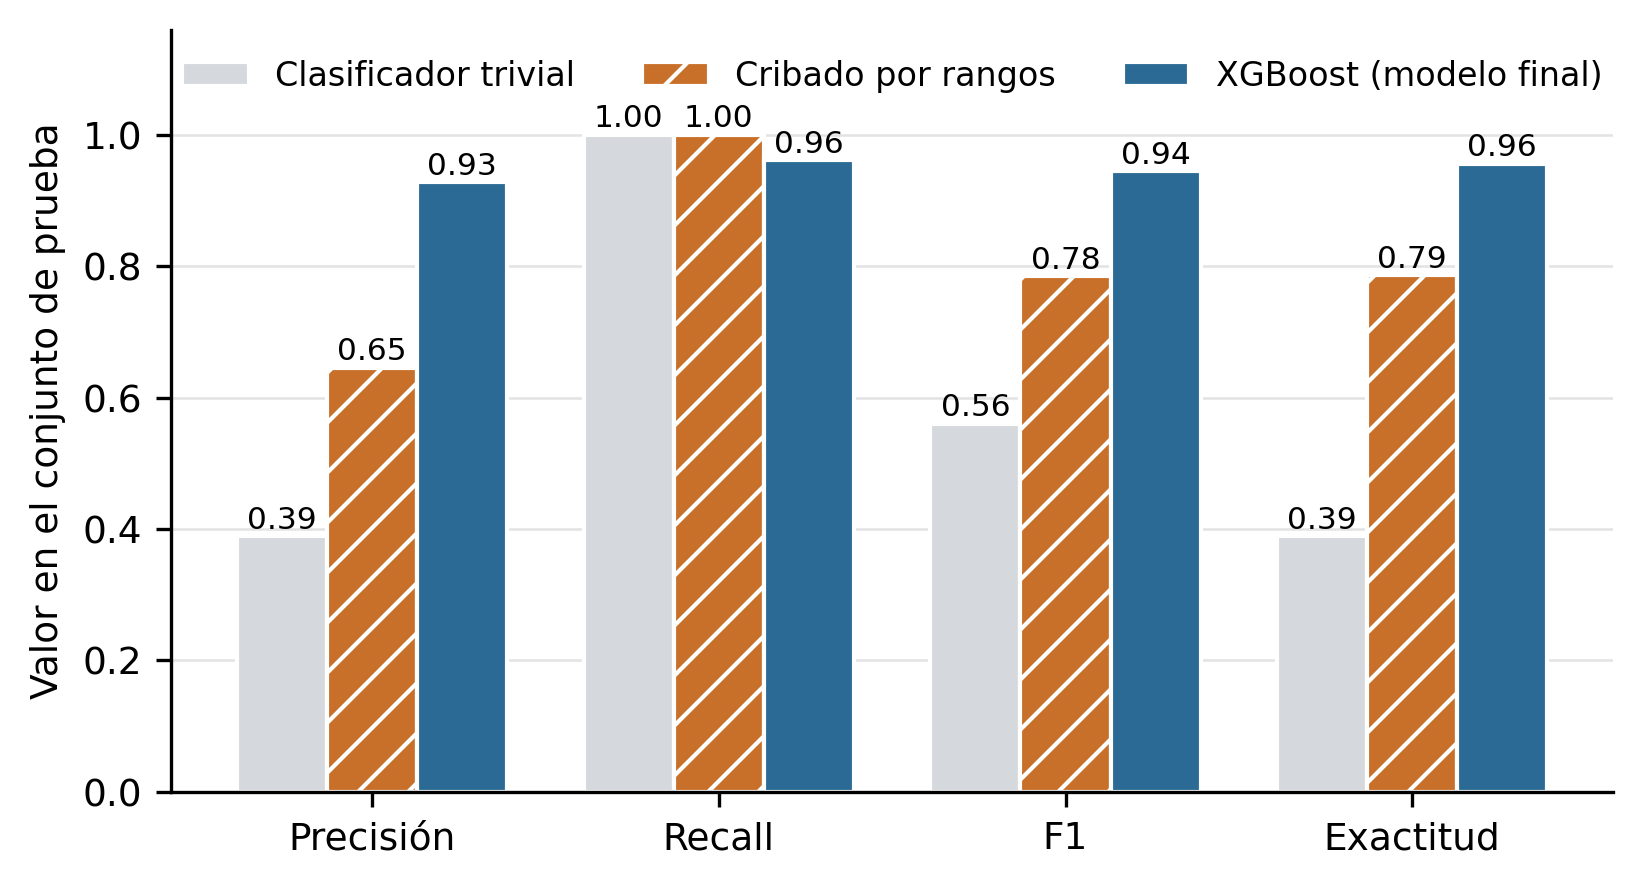

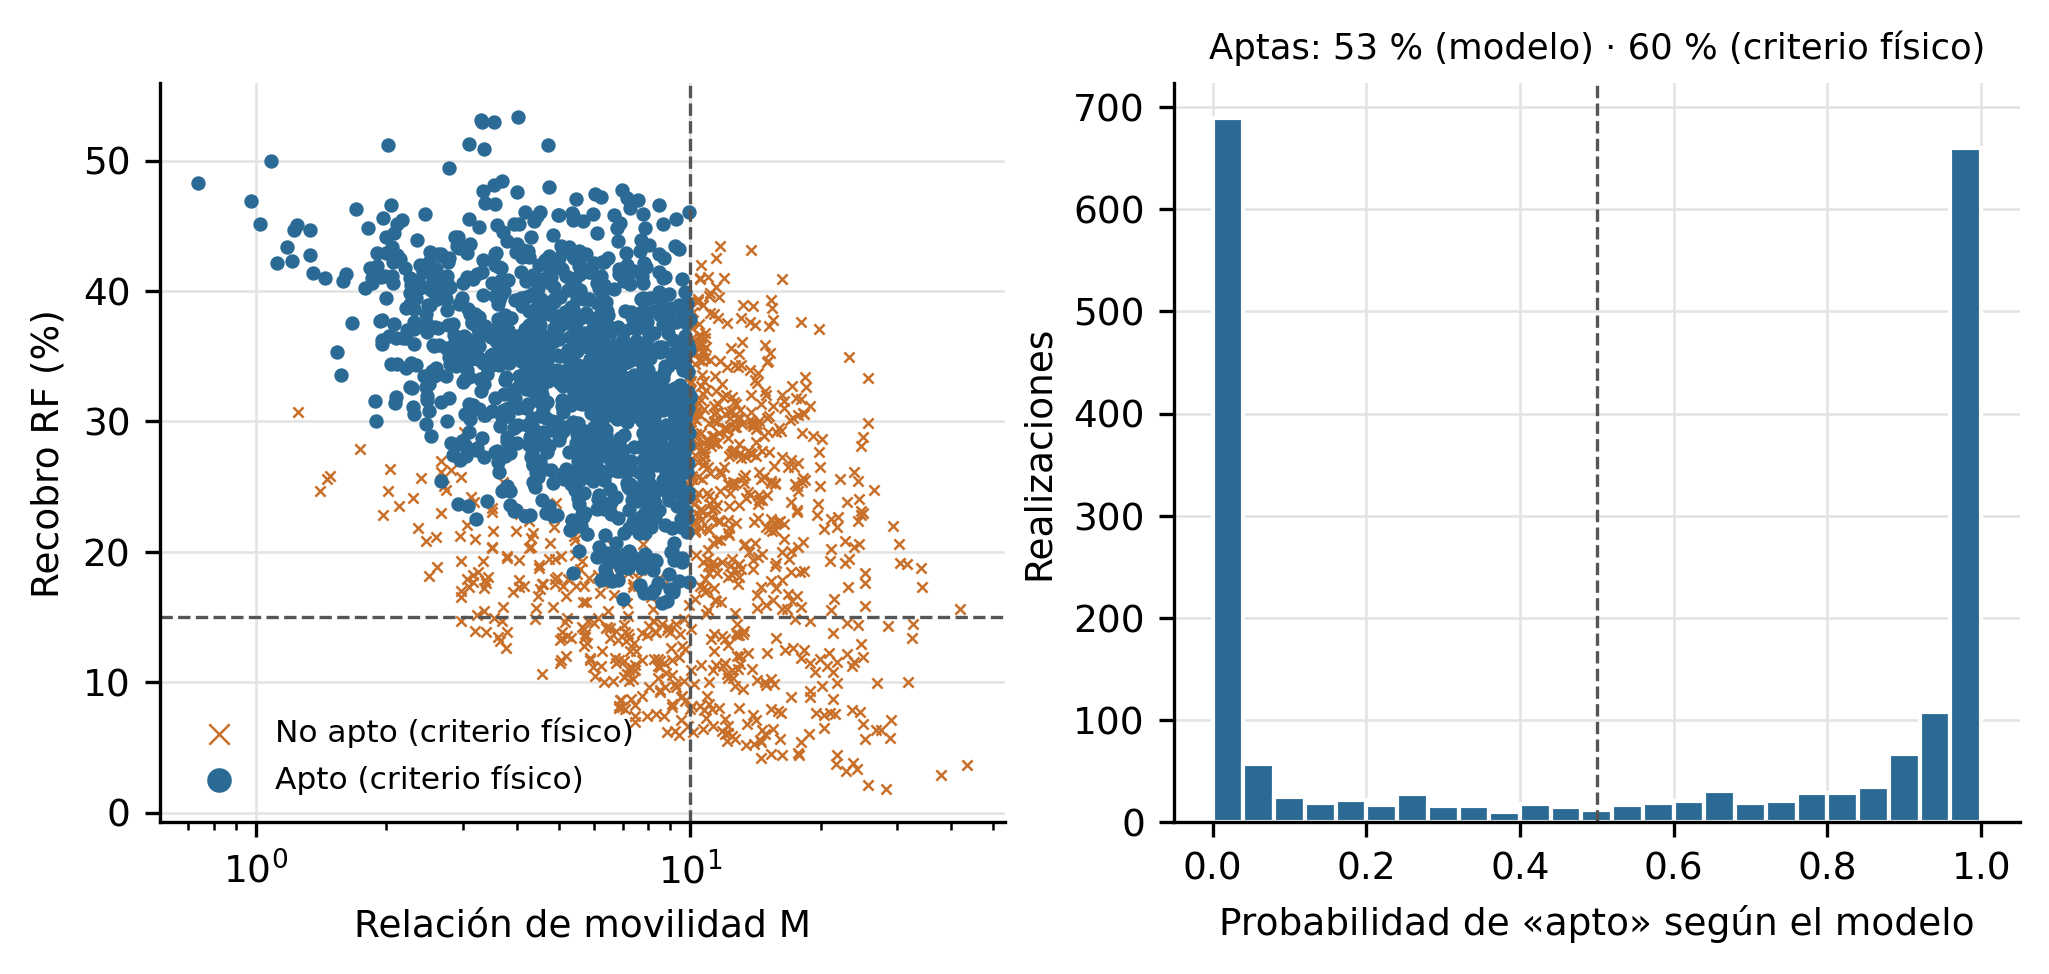

In [9]:
from IPython.display import Image, display
fig_dir = os.path.join(REPO_ROOT, "docs", "figures")
rutas = figures.make_all(resultados, objetos, fig_dir)
ev.save_results(resultados, os.path.join(REPO_ROOT, "results", "etapa5_resultados.json"))
for r in rutas:
    display(Image(r, width=700))

## 8. Verificaciones automáticas

In [10]:
r = subprocess.run([sys.executable, os.path.join(REPO_ROOT, "tests", "test_evaluation.py")], capture_output=True, text=True)
print(r.stdout[-3500:], r.stderr[-1500:])

Verificacion                                                            Resultado
------------------------------------------------------------------------------------
Division 4 000 / 1 000 de la Etapa 3                                    PASA
Entrenamiento y prueba son disjuntos                                    PASA
El modelo usa los hiperparametros guardados en la Etapa 4               PASA
El escalado se ajusto solo con el entrenamiento                         PASA
Todas las metricas estan en [0, 1]                                      PASA
La matriz de confusion suma los 1 000 casos de prueba                   PASA
Precision y recall coinciden con la matriz de confusion                 PASA
La validacion repite el F1 de la Etapa 4                                PASA
AUC-ROC en prueba muy superior al azar (> 0.9)                          PASA
El F1 de prueba no cae mas de 0.05 respecto de la validacion            PASA
El modelo supera al clasificador trivial en la prueba          

## 9. Descargar los resultados

Genera `resultados_etapa5.zip` con el archivo de resultados y las figuras.

In [11]:
import shutil
tmp = "resultados_etapa5"
shutil.rmtree(tmp, ignore_errors=True); os.makedirs(os.path.join(tmp, "docs", "figures")); os.makedirs(os.path.join(tmp, "results"))
shutil.copy(os.path.join(REPO_ROOT, "results", "etapa5_resultados.json"), os.path.join(tmp, "results"))
for r in rutas:
    shutil.copy(r, os.path.join(tmp, "docs", "figures"))
objetos["referencia"].to_csv(os.path.join(tmp, "results", "etapa5_caso_referencia.csv"), index=False)
shutil.make_archive(tmp, "zip", tmp)
try:
    from google.colab import files
    files.download(tmp + ".zip")
except ImportError:
    print("Archivo generado:", os.path.abspath(tmp + ".zip"))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>